In [23]:
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPooling2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator as IDG
import kagglehub
import numpy as np
from sklearn.metrics import (accuracy_score,log_loss, classification_report,confusion_matrix,ConfusionMatrixDisplay)
import matplotlib.pyplot as plt

In [24]:
path = kagglehub.dataset_download("msambare/fer2013")

Using Colab cache for faster access to the 'fer2013' dataset.


In [25]:
model_path = "/content/emotionrecognition.h5"

In [26]:
model = Sequential()
model.add(Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=(48,48,1)))
model.add(Conv2D(64, kernel_size=(3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))
model.add(Conv2D(128, kernel_size=(3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Conv2D(128, kernel_size=(3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))
model.add(Flatten())
model.add(Dense(1024, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(7, activation='softmax'))
model.load_weights(model_path)

In [27]:
print(path)

/kaggle/input/fer2013


In [28]:
from sklearn.utils import shuffle
val_dir = "/kaggle/input/fer2013/test"

batch_size = 64

datagen = IDG(rescale=1./255)

validation_generator = datagen.flow_from_directory(
        val_dir,
        target_size=(48,48),
        batch_size=batch_size,
        color_mode="grayscale",
        class_mode='categorical',
        shuffle=False)

Found 7178 images belonging to 7 classes.


In [29]:
model.compile(loss='categorical_crossentropy',optimizer=Adam(learning_rate=0.0001),metrics=['accuracy'])

113/113 ━━━━━━━━━━━━━━━━━━━━ 31s 271ms/step
Accuracy: 0.6564502646976874
Loss: 0.9389056686918765
              precision    recall  f1-score   support

       angry     0.5750    0.5762    0.5756       958
     disgust     0.7391    0.3063    0.4331       111
        fear     0.5329    0.3877    0.4488      1024
       happy     0.8399    0.8839    0.8613      1774
     neutral     0.5810    0.6894    0.6306      1233
         sad     0.5269    0.5180    0.5224      1247
    surprise     0.7635    0.8002    0.7814       831

    accuracy                         0.6565      7178
   macro avg     0.6512    0.5945    0.6076      7178
weighted avg     0.6515    0.6565    0.6500      7178



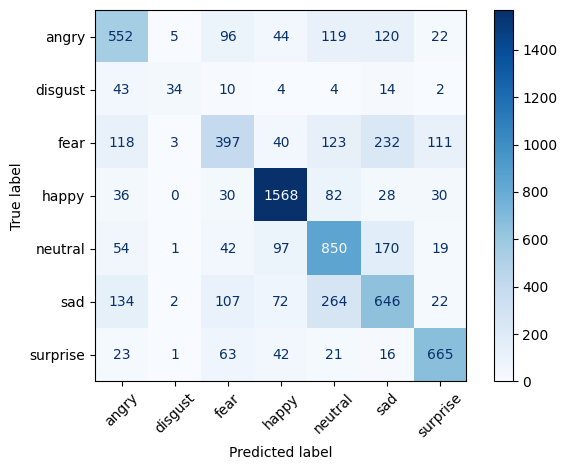

In [30]:
# Get model predictions
y_prob = model.predict(validation_generator, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

# Ground-truth labels (categorical one-hot encoded)
y_true = validation_generator.classes

# Get class names in the correct index order
class_names = [
    name for name, index in sorted(
        validation_generator.class_indices.items(),
        key=lambda item: item[1]
    )
]

# Accuracy & Loss
print("Accuracy:", accuracy_score(y_true, y_pred))
print("Loss:", log_loss(y_true, y_prob, labels=np.arange(y_prob.shape[1])))

# Precision, recall, F1-score for every emotion
print(classification_report(y_true,y_pred,labels=np.arange(len(class_names)),target_names=class_names,zero_division=0,digits=4))

# Confusion matrix
cm = confusion_matrix(y_true,y_pred,labels=np.arange(len(class_names)))
disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=class_names)
disp.plot(xticks_rotation=45, cmap="Blues")
plt.tight_layout()
plt.show()